<h1 style="text-align:center;">Crime Hotspot Prediction</h1>
<h3 style="text-align:center;">Final Year Minor Project</h3>

<table width="100%" style="border:none;">
<tr><td colspan="3" style="text-align:center; border:none;"><b>Department:</b> B.Tech in Data Science</td></tr>
<tr><td colspan="3" style="text-align:center; border:none;"><b>College:</b> Swami Vivekananda University</td></tr>
<tr><td colspan="3" style="text-align:center; border:none;"><b>Session:</b> 2023-2027</td></tr>
<tr><td colspan="3" style="text-align:center; border:none;"><b>Project Guide:</b> Payel Bose</td></tr>
</table>

<br>

<h2 style="text-align:center;">Group Members</h2>

<table align="center" border="1" cellpadding="10" cellspacing="0" style="margin:auto; text-align:center;">
<tr>
<th>Sr. No.</th>
<th>Name</th>
<th>Roll No.</th>
</tr>
<tr>
<td>1</td>
<td>Kousik Chakraborty</td>
<td>002-BTDS-2023-011</td>
</tr>
<tr>
<td>2</td>
<td>Dip Das</td>
<td>002-BTDS-2023-008</td>
</tr>
<tr>
<td>3</td>
<td>Krishna Prasad Sahu</td>
<td>002-BTDS-2023-012</td>
</tr>
<tr>
<td>4</td>
<td>Suryadip Ganguly</td>
<td>002-BTDS-2023-025</td>
</tr>
</table>

## 1. Project Objective
The aim of this project is to:
1. Analyze crime patterns by **time, place, and crime type**
2. Identify **crime hotspots** using spatial analysis (heatmap and DBSCAN clustering)
3. **Predict** the crime count and hotspot status of each 500 m area for the next week using Machine Learning
4. **Compare** three train-test splits (80:20, 70:30 and 85:15) and evaluate the models against simple baselines

## Importing Required Libraries

The following Python libraries are used in this project:

- **Pandas, NumPy:** Data handling, manipulation and numerical calculations.
- **Matplotlib, Seaborn:** Data visualization and statistical charts.
- **Scikit-learn:** DBSCAN clustering, machine learning models, data splitting and model evaluation.
- **XGBoost:** Crime count prediction using the XGBoost regression algorithm.
- **Folium:** Interactive crime hotspot maps and geographical visualization.
- **Warnings:** To control unnecessary warning messages.

In [77]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
pd.set_option("display.max_columns", 30)

## 2. Dataset Description
- **Source:** City of Chicago Data Portal (Crimes, 2001 to Present), Open data
- **Period used:** January to December 2022
- **Size:** 240,512 rows and 22 columns
- **Key columns:** `date`, `primary_type` (crime type), `latitude`, `longitude`, `district`, `beat`, `community_area`, `location_description`, `arrest`, `domestic`
- **Why this dataset:** To the best of our knowledge, publicly available Indian crime data is mostly aggregated at state/district level without coordinates, so a well-documented open dataset with incident-level coordinates was used to build and test the pipeline.

### Loading the Dataset
The dataset is loaded using `pandas`. We check its **shape** (rows and columns), **data types**, and the first few records to understand the structure.

In [78]:
df = pd.read_csv("chicago_crime_2022.csv")
df.head()

,id,case_number,date,block,iucr,primary_type,description,location_description,arrest,domestic,beat,district,ward,community_area,fbi_code,x_coordinate,y_coordinate,year,updated_on,latitude,longitude,location
0,13024128,JG202134,2022-12-31T23:55:00.000,055XX W ADAMS ST,1477,WEAPONS VIOLATION,RECKLESS FIREARM DISCHARGE,RESIDENCE - YARD (FRONT / BACK),False,False,1522,15,29.0,25.0,15,1139642.0,1898786.0,2022,2023-11-15T15:41:31.000,41.878374,-87.762732,"\n, \n(41.878373984, -87.762731975)"
1,12938337,JG100016,2022-12-31T23:50:00.000,014XX W LUNT AVE,0910,MOTOR VEHICLE THEFT,AUTOMOBILE,ALLEY,False,False,2431,24,49.0,1.0,07,1165385.0,1946614.0,2022,2023-01-07T15:41:08.000,42.009108,-87.666844,"\n, \n(42.009107852, -87.666843608)"
2,12938426,JG100085,2022-12-31T23:50:00.000,055XX W WASHINGTON BLVD,0486,BATTERY,DOMESTIC BATTERY SIMPLE,APARTMENT,False,True,1523,15,29.0,25.0,08B,1139357.0,1900199.0,2022,2023-01-07T15:41:08.000,41.882257,-87.763744,"\n, \n(41.882256634, -87.763744015)"
3,12938340,JG100005,2022-12-31T23:47:00.000,091XX S LAFLIN ST,143A,WEAPONS VIOLATION,UNLAWFUL POSSESSION - HANDGUN,APARTMENT,True,False,2221,22,21.0,73.0,15,1167940.0,1844124.0,2022,2023-01-07T15:41:08.000,41.727812,-87.660399,"\n, \n(41.72781203, -87.660399127)"
4,12938351,JG100087,2022-12-31T23:47:00.000,091XX S LAFLIN ST,0560,ASSAULT,SIMPLE,STREET,True,False,2221,22,21.0,73.0,08A,1167940.0,1844124.0,2022,2023-01-07T15:41:08.000,41.727812,-87.660399,"\n, \n(41.72781203, -87.660399127)"


In [79]:
print("Shape:", df.shape)

Shape: (240512, 22)


In [80]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 240512 entries, 0 to 240511
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   id                    240512 non-null  int64  
 1   case_number           240512 non-null  object 
 2   date                  240512 non-null  object 
 3   block                 240512 non-null  object 
 4   iucr                  240512 non-null  object 
 5   primary_type          240512 non-null  object 
 6   description           240512 non-null  object 
 7   location_description  239415 non-null  object 
 8   arrest                240512 non-null  bool   
 9   domestic              240512 non-null  bool   
 10  beat                  240512 non-null  int64  
 11  district              240512 non-null  int64  
 12  ward                  240502 non-null  float64
 13  community_area        240481 non-null  float64
 14  fbi_code              240512 non-null  object 
 15  

**Observation:**
- The dataset contains **240,512 rows** and **22 columns**.
- It covers crimes reported in Chicago during **2022**.
- Columns such as `latitude` and `longitude` contain some missing values, which will be handled in the data cleaning step.

## 3. Data Quality Check
Before analysis, we check the dataset for **missing values** and **duplicate rows**, because they can affect the accuracy of the model.

In [81]:
missing = df.isnull().sum()
print(missing[missing > 0])

location_description    1097
ward                      10
community_area            31
x_coordinate            5621
y_coordinate            5621
latitude                5621
longitude               5621
location                5621
dtype: int64


In [82]:
print("\nDuplicate rows:", df.duplicated().sum())


Duplicate rows: 0


**Observation:**
- Missing values were found in `latitude` and `longitude` (**5,621 rows each**, about **2.3%** of the data), `location_description` (**1,097 rows**), `community_area` (**31 rows**), and `ward` (**10 rows**).
- The columns `x_coordinate`, `y_coordinate`, and `location` have the same 5,621 missing rows, because they store the same location information.
- Number of duplicate rows in the original data: **0** (every record has a unique `id`)
- Rows with missing `latitude`/`longitude` cannot be used for hotspot mapping, so they will be removed in the next step. **234,891** rows have valid coordinates.

## 4. Data Cleaning
The following cleaning steps are applied:
- Selected the **12 useful columns** and dropped ID and duplicate-information columns (`id`, `case_number`, `iucr`, `fbi_code`, `x_coordinate`, `y_coordinate`, `location`, `block`, `year`, `updated_on`)
- Converted `date` to **datetime** format
- Removed rows with **missing latitude/longitude** (about 2.3%), since location is essential for hotspot mapping
- Filled missing `location_description` with "UNKNOWN"
- Removed rows that became exact duplicates after dropping the ID columns

In [83]:
cols = ["date", "primary_type", "description", "latitude", "longitude",
        "district", "beat", "community_area", "ward",
        "location_description", "arrest", "domestic"]
df = df[cols].copy()

df["date"] = pd.to_datetime(df["date"])

before = len(df)
df = df.dropna(subset=["latitude", "longitude"])
print(f"Removed {before - len(df)} rows ({(before - len(df)) / before * 100:.1f}%) with missing coordinates")

df["location_description"] = df["location_description"].fillna("UNKNOWN")
df = df.drop_duplicates().reset_index(drop=True)

print("Final shape:", df.shape)
print("Date range:", df["date"].min(), "to", df["date"].max())

Removed 5621 rows (2.3%) with missing coordinates
Final shape: (234514, 12)
Date range: 2022-01-01 00:00:00 to 2022-12-31 23:55:00


In [84]:
inside = df["latitude"].between(41.6, 42.1) & df["longitude"].between(-88.0, -87.5)
print("Rows outside Chicago:", (~inside).sum())
df = df[inside].reset_index(drop=True)
print("Final shape:", df.shape)

Rows outside Chicago: 2
Final shape: (234512, 12)


**Observation:**
- **5,621 rows (2.3%)** with missing coordinates were removed.
- After selecting the 12 useful columns, **377 rows (0.16%)** were found to be exact duplicates of other rows and were removed.
- **2 rows** with coordinates outside Chicago (wrong location records) were removed.
- The cleaned dataset has **234,512 rows and 12 columns**.
- Data covers **1 January 2022 to 31 December 2022**.

## 5. Feature Engineering
New features were created from `date` (hour, day, month, weekend, night) and from latitude/longitude (500 m grid cells).

In [85]:
df["hour"] = df["date"].dt.hour
df["day_of_week"] = df["date"].dt.dayofweek
df["day_name"] = df["date"].dt.day_name()
df["month"] = df["date"].dt.month
df["is_weekend"] = df["day_of_week"].isin([5, 6]).astype(int)
df["is_night"] = ((df["hour"] >= 20) | (df["hour"] <= 5)).astype(int)

df[["date", "hour", "day_name", "month", "is_weekend", "is_night"]].head()

,date,hour,day_name,month,is_weekend,is_night
0,2022-12-31 23:55:00,23,Saturday,12,1,1
1,2022-12-31 23:50:00,23,Saturday,12,1,1
2,2022-12-31 23:50:00,23,Saturday,12,1,1
3,2022-12-31 23:47:00,23,Saturday,12,1,1
4,2022-12-31 23:47:00,23,Saturday,12,1,1


**Grid cells (base for hotspots)**

In [86]:
df["lat_grid"] = (df["latitude"] / 0.0045).round().astype(int)
df["lon_grid"] = (df["longitude"] / 0.006).round().astype(int)
df["cell_id"] = df["lat_grid"].astype(str) + "_" + df["lon_grid"].astype(str)

cell_counts = df["cell_id"].value_counts()
top10 = int(len(cell_counts) * 0.10)
print("Total grid cells:", len(cell_counts))
print(f"Top 10% of cells hold {cell_counts.head(top10).sum() / cell_counts.sum() * 100:.1f}% of all crimes")

Total grid cells: 2304
Top 10% of cells hold 34.1% of all crimes


**Observation:**
- New time features: hour, day of week, month, weekend flag, night flag.
- The city is divided into **2304 grid cells** of about 500 m x 500 m.
- The busiest 10% of cells hold **34.1%** of all crimes, so crime is concentrated in a few places.

## 6. Exploratory Data Analysis
We study crime patterns by **type, time and location**.

**Top crime types**

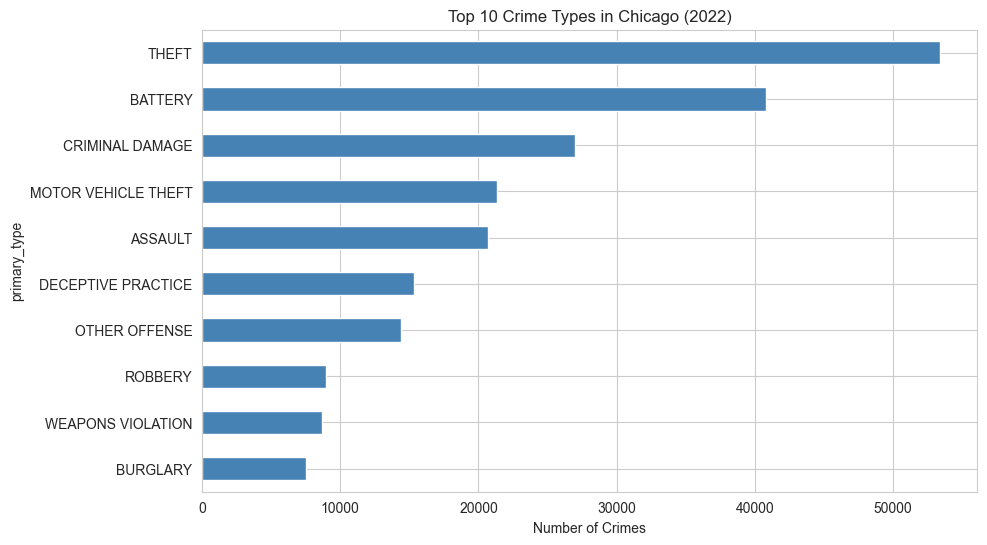

In [87]:
plt.figure(figsize=(10, 6))
df["primary_type"].value_counts().head(10).sort_values().plot.barh(color="steelblue")
plt.title("Top 10 Crime Types in Chicago (2022)")
plt.xlabel("Number of Crimes")
plt.show()

**Hour, month, and day charts**

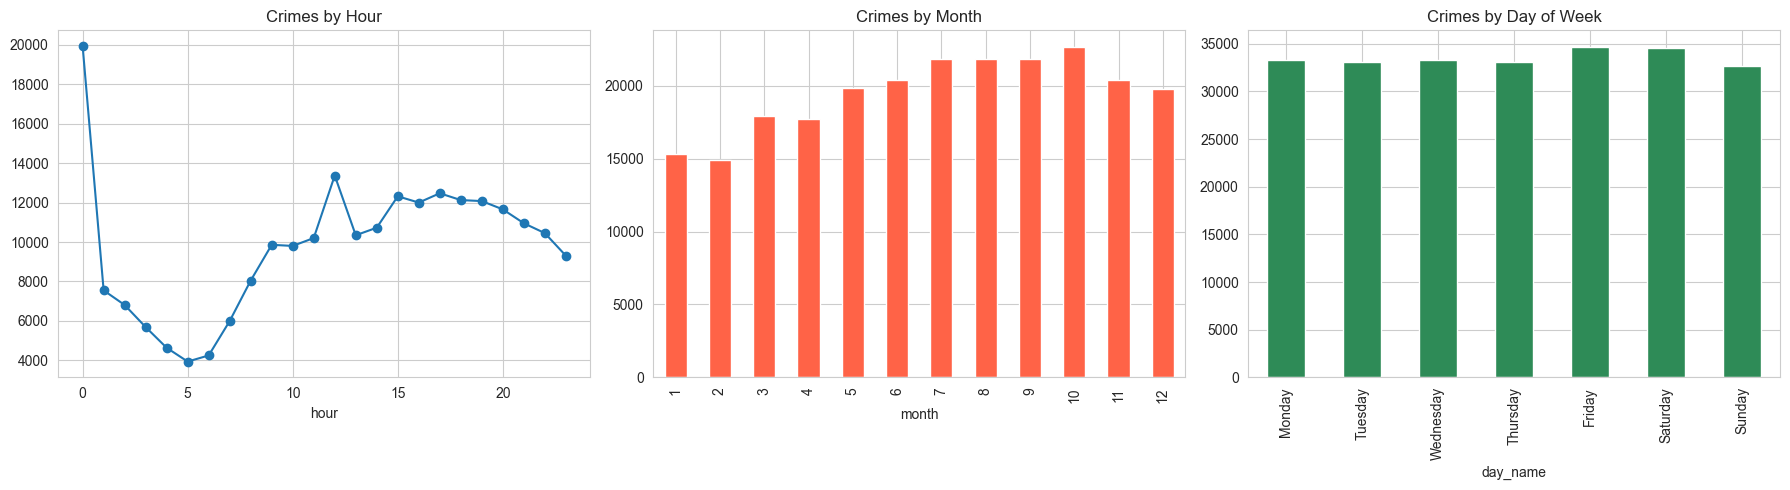

In [88]:
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
df["hour"].value_counts().sort_index().plot(ax=ax[0], marker="o")
ax[0].set_title("Crimes by Hour")
df["month"].value_counts().sort_index().plot.bar(ax=ax[1], color="tomato")
ax[1].set_title("Crimes by Month")
df["day_name"].value_counts().reindex(order).plot.bar(ax=ax[2], color="seagreen")
ax[2].set_title("Crimes by Day of Week")
plt.tight_layout()
plt.show()

**Heatmap of day vs hour**

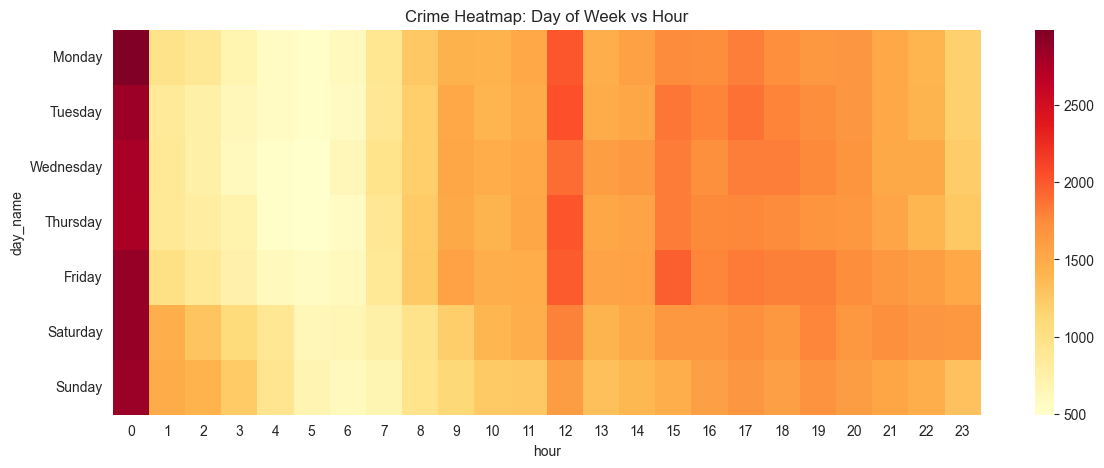

In [89]:
pivot = df.pivot_table(index="day_name", columns="hour",
                       values="primary_type", aggfunc="count").reindex(order)
plt.figure(figsize=(14, 5))
sns.heatmap(pivot, cmap="YlOrRd")
plt.title("Crime Heatmap: Day of Week vs Hour")
plt.show()

**Crime locations on a plain map**

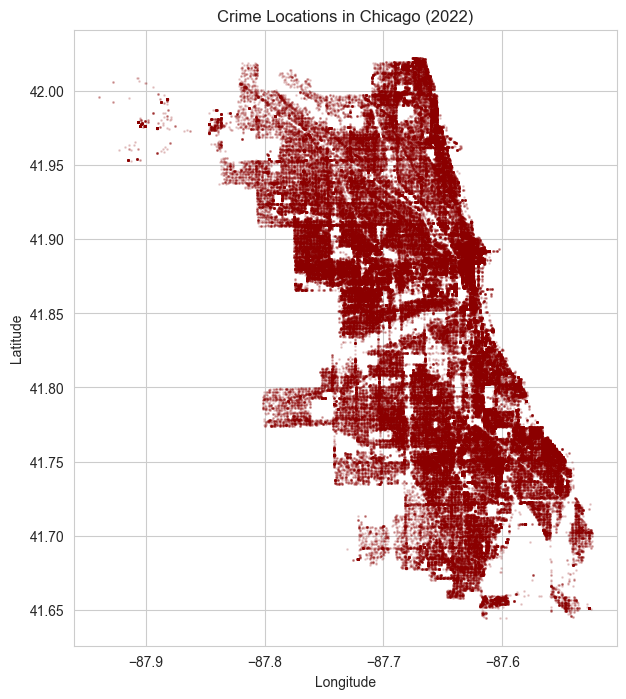

In [90]:
plt.figure(figsize=(7, 8))
plt.scatter(df["longitude"], df["latitude"], s=1, alpha=0.15, color="darkred")
plt.title("Crime Locations in Chicago (2022)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

**top crime types by month**

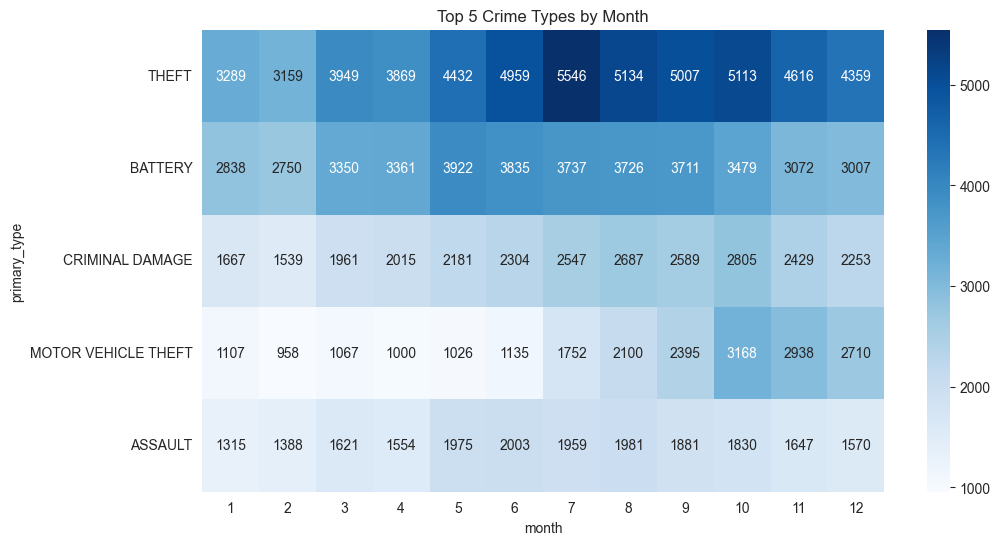

In [91]:
top5 = df["primary_type"].value_counts().head(5).index
plt.figure(figsize=(11, 6))
sns.heatmap(df.pivot_table(index="primary_type", columns="month", values="hour",
                           aggfunc="count").loc[top5], annot=True, fmt=".0f", cmap="Blues")
plt.title("Top 5 Crime Types by Month")
plt.show()

## Observations (EDA)

- **Most common crime type:** **Theft** (about 53,000 crimes), followed by **Battery** and **Criminal Damage**.
- **By hour:** crime is lowest at about **5 AM** and rises through the day to an evening peak at **3 to 7 PM**.
- **Hour 0 (midnight)** and **hour 12 (noon)** show unusual spikes. These are **data recording artefacts**: when the exact time of a crime is unknown, it is often stored as 00:00 or 12:00. So they do not prove that crime is really highest at these hours.
- **By month:** crime is highest in **October** and lowest in **February**. It rises from winter to summer and autumn.
- **By day of week:** crime is almost the same on all days. **Friday and Saturday** are slightly higher and **Sunday** is slightly lower.
- **Crime type by month:** **Theft** peaks in **July** (5,546). **Battery** peaks in **May**. **Motor Vehicle Theft** is low until June and then rises strongly to its peak in **October** (3,168).
- **Locations:** the scatter plot shows that crime covers the whole city but is **very dense in some parts**. The busiest **10% of grid cells hold 34.1%** of all crimes.

## 7. Machine Learning: Predicting Crime Hotspots
**Problem:** Using the past 4 weeks of crime history of each 500 m grid cell, predict (a) how many crimes will occur next week (**regression**) and (b) whether the cell will be a **hotspot** (classification).

- **Weeks used:** only the 52 complete weeks (1 Jan to 30 Dec 2022). 31 Dec is a single day, so it is excluded.
- **Train/Test split:** time-based (no shuffling), so the model never sees future data. Three splits are compared: **80:20, 70:30 and 85:15**.
- **Hotspot definition:** a cell-week is a hotspot if its crime count is above the 80th percentile of the **training** data.
- **Baselines:** last week's count, and the 4-week average.

In [92]:
from sklearn.model_selection import train_test_split

start = df["date"].min().normalize()
df["week_idx"] = (df["date"].dt.normalize() - start).dt.days // 7

# 31 Dec is alone in week 52, so only the 52 full weeks (0 to 51) are used
d = df[df["week_idx"] < 52].copy()

# Select training weeks for active cell selection
usable_weeks = sorted(d["week_idx"].unique())[4:]

train_weeks_70, _ = train_test_split(
    usable_weeks,
    train_size=0.70,
    shuffle=False
)

# Select active cells using training data only
active_counts = d[
    d["week_idx"].isin(train_weeks_70)
]["cell_id"].value_counts()

active = active_counts[active_counts >= 30].index

panel = (
    d[d["cell_id"].isin(active)]
    .groupby(["cell_id", "week_idx"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=range(52), fill_value=0)
    .stack()
    .reset_index(name="crime_count")
)

print("Active cells:", len(active), "| Panel shape:", panel.shape)
print("Training weeks used:", len(train_weeks_70))

Active cells: 1458 | Panel shape: (75816, 3)
Training weeks used: 33


In [93]:
g = panel.groupby("cell_id")["crime_count"]

for k in range(1, 5):
    panel[f"lag_{k}"] = g.shift(k)

panel["roll_4_mean"] = g.transform(
    lambda s: s.shift(1).rolling(4).mean()
)

centers = d.groupby("cell_id")[["latitude", "longitude"]].mean()
centers.columns = ["cell_lat", "cell_lon"]

panel = panel.join(centers, on="cell_id")

panel["month"] = (
    start + pd.to_timedelta(panel["week_idx"] * 7, unit="D")
).dt.month

panel = panel.dropna().reset_index(drop=True)

features = [
    "lag_1", "lag_2", "lag_3", "lag_4",
    "roll_4_mean", "month", "cell_lat", "cell_lon"
]

panel.head()

,cell_id,week_idx,crime_count,lag_1,lag_2,lag_3,lag_4,roll_4_mean,cell_lat,cell_lon,month
0,9256_-14588,4,0,0.0,1.0,2.0,2.0,1.25,41.651453,-87.52727,1
1,9256_-14588,5,1,0.0,0.0,1.0,2.0,0.75,41.651453,-87.52727,2
2,9256_-14588,6,2,1.0,0.0,0.0,1.0,0.50,41.651453,-87.52727,2
3,9256_-14588,7,0,2.0,1.0,0.0,0.0,0.75,41.651453,-87.52727,2
4,9256_-14588,8,3,0.0,2.0,1.0,0.0,0.75,41.651453,-87.52727,2


In [94]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

weeks = sorted(panel["week_idx"].unique())

split_ratios = [0.80, 0.70, 0.85]

all_results = []
rf_80 = None

for ratio in split_ratios:

    train_weeks, test_weeks = train_test_split(
        weeks,
        train_size=ratio,
        shuffle=False
    )

    print(
        f"Split: {int(ratio*100)}:{100-int(ratio*100)} | "
        f"Train weeks: {len(train_weeks)} | "
        f"Test weeks: {len(test_weeks)}"
    )

    train = panel[panel["week_idx"].isin(train_weeks)]
    test = panel[panel["week_idx"].isin(test_weeks)]

    X_train, y_train = train[features], train["crime_count"]
    X_test, y_test = test[features], test["crime_count"]

    def evaluate(name, pred):
        return {
            "Split": f"{int(ratio*100)}:{100-int(ratio*100)}",
            "Model": name,
            "MAE": mean_absolute_error(y_test, pred),
            "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
            "R2": r2_score(y_test, pred)
        }

    # Baseline models
    all_results.append(
        evaluate("Baseline (last week)", test["lag_1"])
    )

    all_results.append(
        evaluate("Baseline (4-week average)", test["roll_4_mean"])
    )

    # Random Forest
    rf = RandomForestRegressor(
        n_estimators=200,
        max_depth=12,
        n_jobs=-1,
        random_state=42
    )

    rf.fit(X_train, y_train)

    all_results.append(
        evaluate("Random Forest", rf.predict(X_test))
    )

    if ratio == 0.80:
        rf_80 = rf

    # XGBoost
    xgb = XGBRegressor(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        random_state=42
    )

    xgb.fit(X_train, y_train)

    all_results.append(
        evaluate("XGBoost", xgb.predict(X_test))
    )

regression_results = pd.DataFrame(all_results)

print(regression_results.round(3))


Split: 80:20 | Train weeks: 38 | Test weeks: 10
Split: 70:30 | Train weeks: 33 | Test weeks: 15
Split: 85:15 | Train weeks: 40 | Test weeks: 8
    Split                      Model    MAE   RMSE     R2
0   80:20       Baseline (last week)  1.921  2.635  0.212
1   80:20  Baseline (4-week average)  1.604  2.153  0.474
2   80:20              Random Forest  1.580  2.234  0.434
3   80:20                    XGBoost  1.565  2.215  0.443
4   70:30       Baseline (last week)  1.939  2.646  0.222
5   70:30  Baseline (4-week average)  1.609  2.150  0.486
6   70:30              Random Forest  1.590  2.184  0.470
7   70:30                    XGBoost  1.575  2.156  0.483
8   85:15       Baseline (last week)  1.895  2.608  0.197
9   85:15  Baseline (4-week average)  1.592  2.133  0.463
10  85:15              Random Forest  1.575  2.242  0.407
11  85:15                    XGBoost  1.563  2.201  0.428


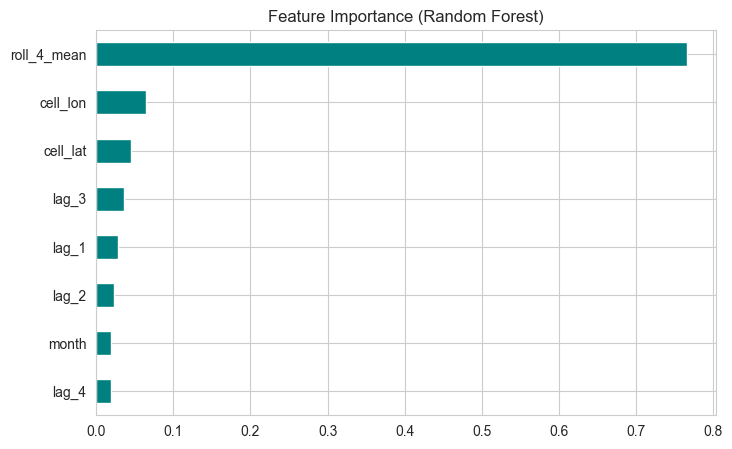

In [95]:
imp = pd.Series(rf_80.feature_importances_, index=features).sort_values()
imp.plot.barh(figsize=(8, 5), color="teal", title="Feature Importance (Random Forest)")
plt.show()

In [96]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, roc_auc_score, accuracy_score

classification_results = []

for ratio in split_ratios:

    train_weeks, test_weeks = train_test_split(
        weeks,
        train_size=ratio,
        shuffle=False
    )

    train = panel[panel["week_idx"].isin(train_weeks)]
    test = panel[panel["week_idx"].isin(test_weeks)]

    X_train, y_train = train[features], train["crime_count"]
    X_test, y_test = test[features], test["crime_count"]

    # Same hotspot threshold for all splits (from first 70% weeks of training data)
    thr = panel[panel["week_idx"].isin(train_weeks_70)]["crime_count"].quantile(0.80)

    y_train_c = (y_train > thr).astype(int)
    y_test_c = (y_test > thr).astype(int)

    clf = RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        class_weight="balanced",
        n_jobs=-1,
        random_state=42
    )

    clf.fit(X_train, y_train_c)

    pred = clf.predict(X_test)
    prob = clf.predict_proba(X_test)[:, 1]

    baseline_pred = (test["lag_1"] > thr).astype(int)

    classification_results.append({
        "Split": f"{int(ratio*100)}:{100-int(ratio*100)}",
        "Threshold": thr,
        "Accuracy": accuracy_score(y_test_c, pred),
        "F1 Score": f1_score(y_test_c, pred),
        "ROC-AUC": (
            roc_auc_score(y_test_c, prob)
            if y_test_c.nunique() == 2 else np.nan
        ),
        "Baseline F1": f1_score(y_test_c, baseline_pred)
    })

classification_df = pd.DataFrame(classification_results)

print(classification_df.round(3))


   Split  Threshold  Accuracy  F1 Score  ROC-AUC  Baseline F1
0  80:20        4.0     0.777     0.568    0.820        0.500
1  70:30        4.0     0.782     0.579    0.823        0.507
2  85:15        4.0     0.771     0.554    0.825        0.496


Split                      70:30  80:20  85:15
Model                                         
Baseline (4-week average)  1.609  1.604  1.592
Baseline (last week)       1.939  1.921  1.895
Random Forest              1.590  1.580  1.575
XGBoost                    1.575  1.565  1.563


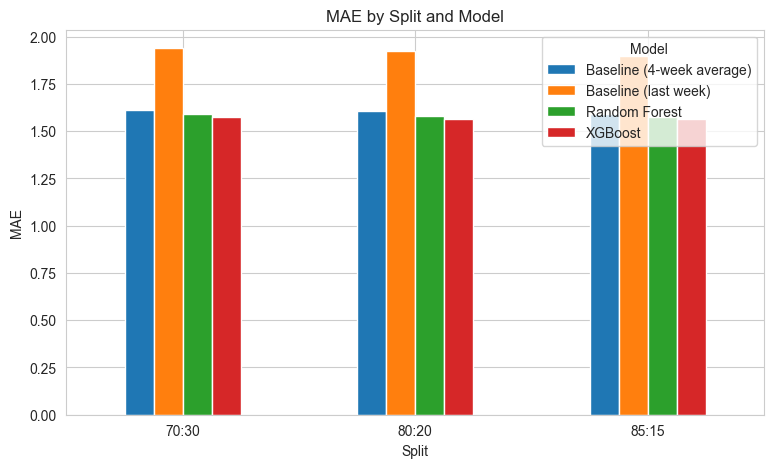

In [97]:
summary = regression_results.pivot(index="Model", columns="Split", values="MAE").round(3)
print(summary)
summary.T.plot(kind="bar", figsize=(9,5), title="MAE by Split and Model")
plt.ylabel("MAE"); plt.xticks(rotation=0); plt.show()

### Comparison of the Three Train/Test Splits
The charts below compare **R²** (regression) and **F1 Score** (hotspot classification) for the **80:20, 70:30 and 85:15** splits.

R2 by split and model
Split                      70:30  80:20  85:15
Model                                         
Baseline (4-week average)  0.486  0.474  0.463
Baseline (last week)       0.222  0.212  0.197
Random Forest              0.470  0.434  0.407
XGBoost                    0.483  0.443  0.428


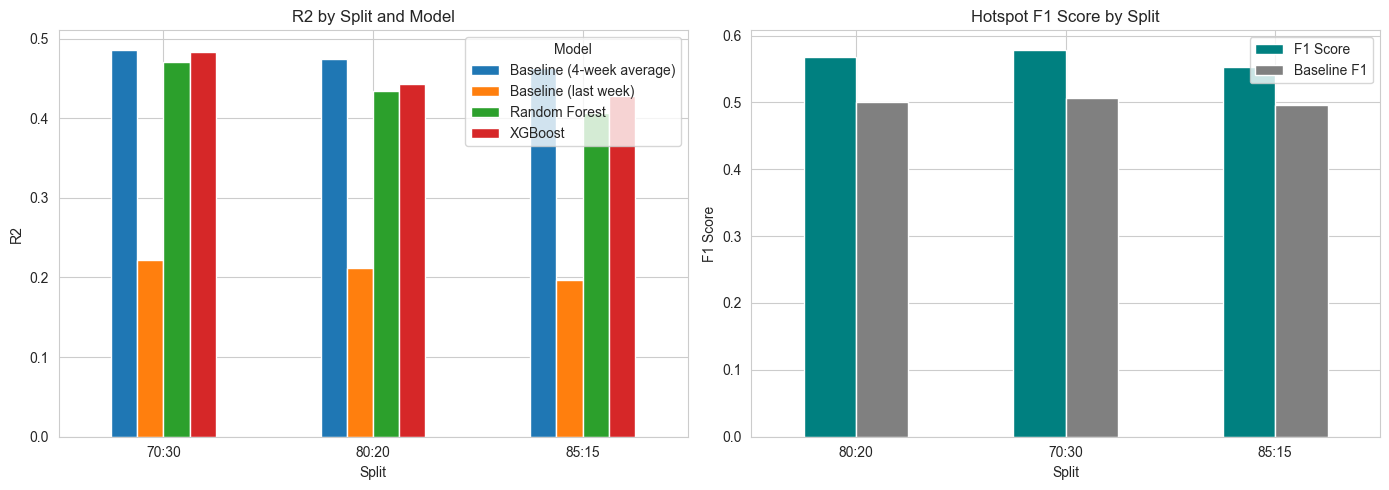

In [98]:
r2 = regression_results.pivot(index="Model", columns="Split", values="R2").round(3)
print("R2 by split and model")
print(r2)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
r2.T.plot(kind="bar", ax=ax[0], title="R2 by Split and Model")
ax[0].set_ylabel("R2"); ax[0].tick_params(axis="x", rotation=0)

classification_df.set_index("Split")[["F1 Score", "Baseline F1"]].plot(
    kind="bar", ax=ax[1], color=["teal", "gray"], title="Hotspot F1 Score by Split")
ax[1].set_ylabel("F1 Score"); ax[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

### Observation (Train/Test Split Comparison)

**Regression (next-week crime count):**
- **XGBoost** has the **lowest MAE in all three splits** (1.565, 1.575 and 1.563), slightly better than Random Forest and clearly better than the "last week" baseline (about 1.9).
- However, the simple **4-week average baseline** is very strong. Its R² (0.474, 0.486, 0.463) is **similar to or higher than** XGBoost (0.443, 0.483, 0.428). This means crime in a cell changes slowly, so the recent average already explains most of the pattern.
- **"Last week" baseline is the weakest** (R² about 0.2), because a single week is noisy.

**Classification (hotspot or not):**
- The Random Forest classifier gets **F1 = 0.568 (80:20), 0.579 (70:30), 0.554 (85:15)** and **ROC-AUC about 0.82** in all splits. It **beats the baseline F1 (about 0.50) in every split**.
- The **same hotspot threshold (4 crimes per cell-week)** is used in all three splits, so the comparison is fair.

**Overall:** the three splits give **very similar results**. The 70:30 split is slightly best, but the differences are small. A larger test set (30%) covers more weeks, so it is also the most reliable estimate. The **80:20 split** is used as the main split for the detailed analysis below.

### Detailed Hotspot Classification Results (80:20 split)
The **classification report**, **confusion matrix** and **ROC curve** show how well the model separates hotspot cells from normal cells.

Hotspot threshold: 4.0
              precision    recall  f1-score   support

 Not hotspot       0.91      0.80      0.85     11496
     Hotspot       0.48      0.69      0.57      3084

    accuracy                           0.78     14580
   macro avg       0.69      0.75      0.71     14580
weighted avg       0.82      0.78      0.79     14580



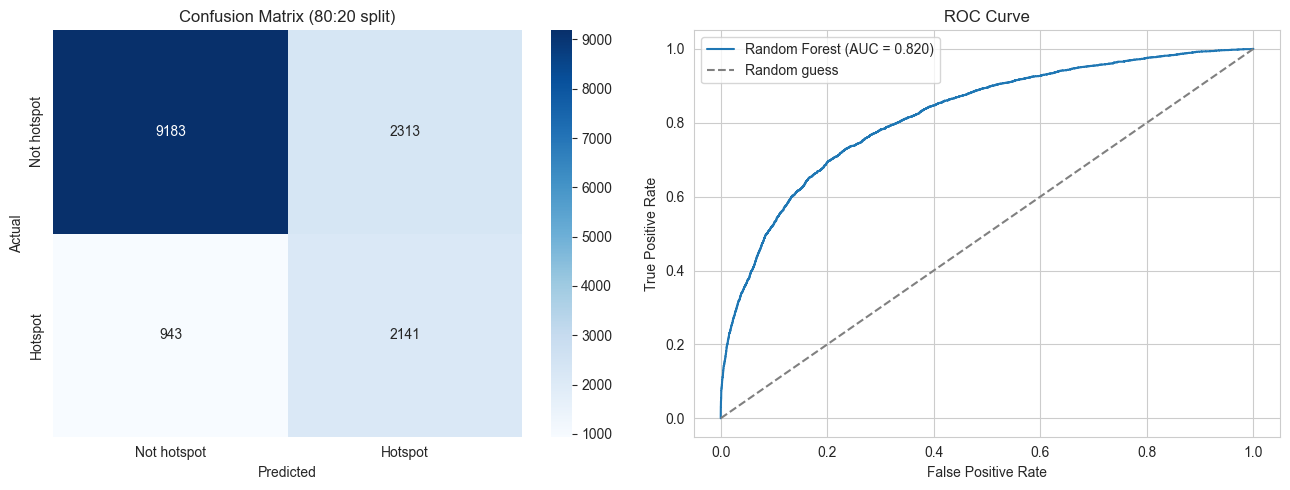

In [99]:
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, roc_auc_score

train_weeks, test_weeks = train_test_split(weeks, train_size=0.80, shuffle=False)
train = panel[panel["week_idx"].isin(train_weeks)]
test = panel[panel["week_idx"].isin(test_weeks)].copy()

thr = panel[panel["week_idx"].isin(train_weeks_70)]["crime_count"].quantile(0.80)
y_train_c = (train["crime_count"] > thr).astype(int)
y_test_c = (test["crime_count"] > thr).astype(int)

clf80 = RandomForestClassifier(n_estimators=200, max_depth=12,
                               class_weight="balanced", n_jobs=-1, random_state=42)
clf80.fit(train[features], y_train_c)

test["pred_hotspot"] = clf80.predict(test[features])
test["prob_hotspot"] = clf80.predict_proba(test[features])[:, 1]
test["actual_hotspot"] = y_test_c

print("Hotspot threshold:", thr)
print(classification_report(y_test_c, test["pred_hotspot"],
                            target_names=["Not hotspot", "Hotspot"]))

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

cm = confusion_matrix(y_test_c, test["pred_hotspot"])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax[0],
            xticklabels=["Not hotspot", "Hotspot"],
            yticklabels=["Not hotspot", "Hotspot"])
ax[0].set_title("Confusion Matrix (80:20 split)")
ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("Actual")

fpr, tpr, _ = roc_curve(y_test_c, test["prob_hotspot"])
ax[1].plot(fpr, tpr, label=f"Random Forest (AUC = {roc_auc_score(y_test_c, test['prob_hotspot']):.3f})")
ax[1].plot([0, 1], [0, 1], "--", color="gray", label="Random guess")
ax[1].set_title("ROC Curve")
ax[1].set_xlabel("False Positive Rate"); ax[1].set_ylabel("True Positive Rate")
ax[1].legend()
plt.tight_layout()
plt.show()

In [100]:
K = 50
model_hits, base_hits = [], []

for w, g in test.groupby("week_idx"):
    model_hits.append(g.nlargest(K, "prob_hotspot")["actual_hotspot"].mean())
    base_hits.append(g.nlargest(K, "lag_1")["actual_hotspot"].mean())

print(f"Top-{K} hit rate (model)           : {np.mean(model_hits):.3f}")
print(f"Top-{K} hit rate (last-week rule)  : {np.mean(base_hits):.3f}")

Top-50 hit rate (model)           : 0.866
Top-50 hit rate (last-week rule)  : 0.792


### Observation (Classification Details)

- The model's **recall for hotspots is 0.69** and **precision is 0.48**. This means it finds about **69%** of the real hotspot cells, and about **48%** of the cells it marks as hotspots are really hotspots.
- The confusion matrix shows **2,141 hotspot cells correctly detected** and **943 missed** (out of 3,084 real hotspot cells). It also gives **2,313 false alarms**.
- The **ROC curve is far above the random-guess line** (AUC = **0.820**), so the model separates hotspot and normal cells well.
- **Top-50 hit rate:** if the police checked only the 50 cells with the highest predicted risk each week, **86.6%** of them would be real hotspots, compared to **79.2%** using the simple "last week" rule.
- Because `class_weight="balanced"` is used, the model catches more hotspots (higher recall) but also gives some **false alarms** (lower precision). For patrol planning, missing a hotspot is usually worse than a false alarm.
- Overall accuracy is **78%**, and the hotspot **F1 score is 0.57**.

### Predicted vs Actual Hotspots (Last Test Week)
The left map shows the cells that were **actually** hotspots in the last test week, and the right map shows the cells our model **predicted** as hotspots.

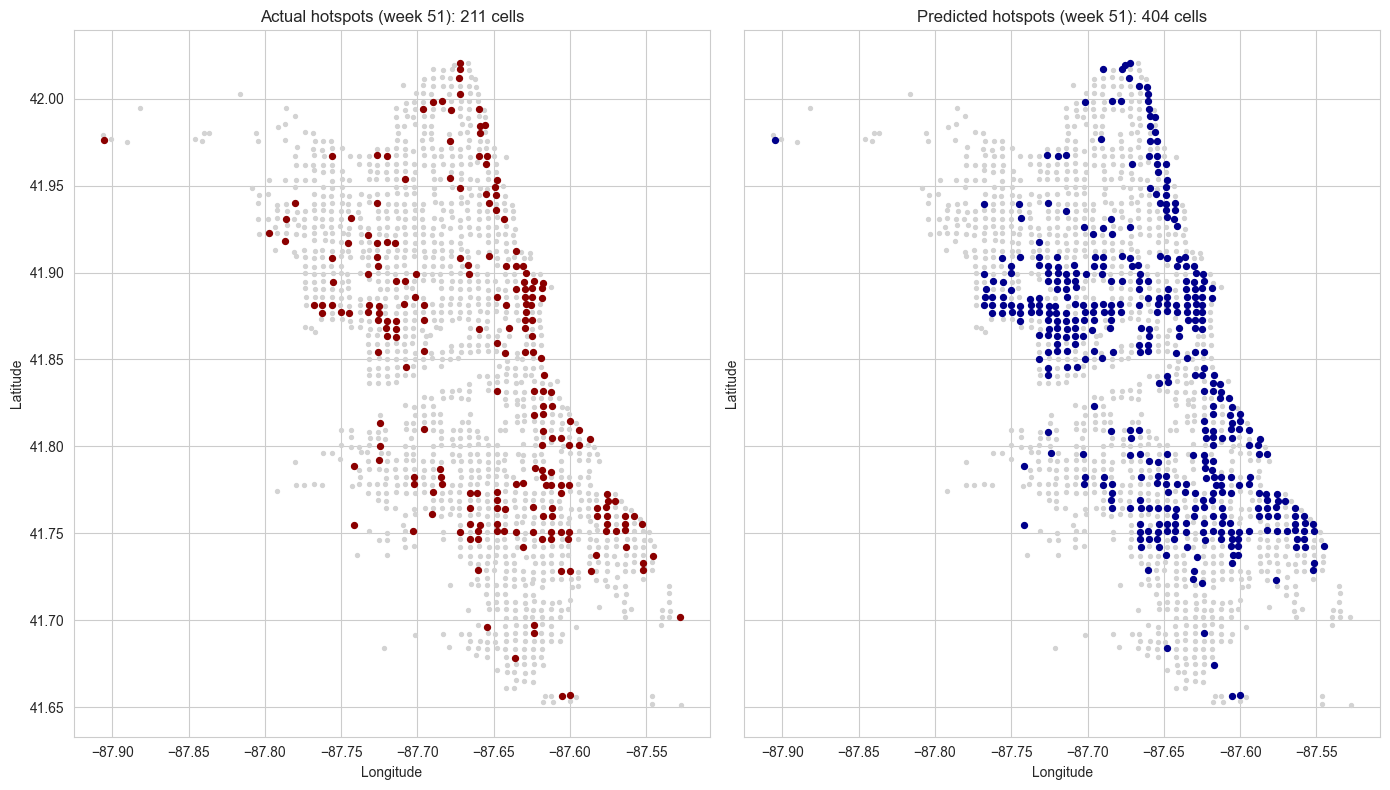

In [101]:
last_week = test["week_idx"].max()
lw = test[test["week_idx"] == last_week]

fig, ax = plt.subplots(1, 2, figsize=(14, 8), sharex=True, sharey=True)

for a, col, title, color in [
    (ax[0], "actual_hotspot", f"Actual hotspots (week {last_week})", "darkred"),
    (ax[1], "pred_hotspot", f"Predicted hotspots (week {last_week})", "darkblue")]:
    a.scatter(lw["cell_lon"], lw["cell_lat"], s=8, color="lightgray")
    h = lw[lw[col] == 1]
    a.scatter(h["cell_lon"], h["cell_lat"], s=18, color=color)
    a.set_title(f"{title}: {len(h)} cells")
    a.set_xlabel("Longitude"); a.set_ylabel("Latitude")

plt.tight_layout()
plt.show()

**Observation:**
- The predicted hotspots (right) are in the **same broad areas** as the actual hotspots (left): the **central and west side** of the city, the **lakefront** and the **south-east**.
- The model predicts **404 hotspot cells** against **211 actual ones**, so it predicts almost **twice as many** hotspots as really occurred. This is because of `class_weight="balanced"`, which makes the model prefer catching hotspots over avoiding false alarms.
- Actual hotspots are more **scattered**, while predicted hotspots form **solid, connected areas**. So the model is good at finding **high-risk areas**, but less exact about **which single cell** will be a hotspot in a particular week.

## 8. Hotspot Detection

In this stage, we identify geographical areas with high crime concentration using spatial analysis techniques.

The following techniques are used:

- **Folium Heatmap:** Visualize crime concentration on an interactive map.
- **DBSCAN Clustering:** Group the busiest hotspot cells that are close to each other into connected **hotspot zones**.

In [102]:
import folium
from folium.plugins import HeatMap

In [103]:
heat_data = (
    df.groupby("cell_id")
    .agg(
        latitude=("latitude", "mean"),
        longitude=("longitude", "mean"),
        crime_count=("cell_id", "count")
    )
    .reset_index()
)

heat_data.head()

,cell_id,latitude,longitude,crime_count
0,9254_-14599,41.644595,-87.596781,1
1,9254_-14600,41.644612,-87.601570,1
2,9254_-14602,41.644608,-87.613582,3
3,9254_-14603,41.645156,-87.615138,1
4,9255_-14589,41.649625,-87.536242,1


In [104]:
m = folium.Map(
    location=[
        df["latitude"].mean(),
        df["longitude"].mean()
    ],
    zoom_start=11,
    tiles="OpenStreetMap"
)


In [105]:
HeatMap(
    data=heat_data[
        ["latitude", "longitude", "crime_count"]
    ].values.tolist(),
    radius=18,
    blur=15,
    max_zoom=13
).add_to(m)

m

**Crime Heatmap of Chicago (2022)**

![Heatmap](heatmap.png)

In [106]:
m.save("chicago_crime_heatmap.html")

**Observation:**

- The Folium heat map shows that crime is **not spread evenly**. Red and orange zones form a **large connected belt** along the **lakefront** and across the **central, west and south sides** of the city.
- The **brightest (red) spot** is near the **downtown/Loop area**, where crime counts are highest.
- Cooler zones (yellow, green and blue) appear mainly at the **north-west edge** (near the airport) and at the **outer edges** of the city.
- The heat is concentrated **inside the Chicago city boundary**. The suburbs and the lake show no heat, because the dataset contains only crimes reported in Chicago.
- This matches the earlier finding that the busiest **10% of grid cells hold 34.1%** of all crimes.
- The heat map is made from crime counts of 500 m grid cells, so it shows **where** crime is concentrated but not **when**. The prediction model handles the **when**.

## 9. DBSCAN Clustering

**DBSCAN** (Density-Based Spatial Clustering of Applications with Noise) groups nearby points into clusters and marks isolated points as **noise**.

Running DBSCAN on all 2.3 lakh crime points joins the whole city into one huge cluster, because crimes are everywhere. So we apply DBSCAN on the **hotspot cells only** (the busiest **top 10%** of 500 m grid cells) with **eps = 0.8 km** and **min_samples = 3**. This shows which hotspot cells form **connected hotspot zones**.

In [107]:
from sklearn.cluster import DBSCAN

# Hotspot cells = top 10% busiest grid cells
cell_counts = df["cell_id"].value_counts()
top_cells = cell_counts.head(int(len(cell_counts) * 0.10)).index

cells = (df[df["cell_id"].isin(top_cells)]
         .groupby("cell_id")
         .agg(latitude=("latitude", "mean"),
              longitude=("longitude", "mean"),
              crimes=("cell_id", "count"))
         .reset_index())

# DBSCAN with haversine distance: eps = 0.8 km, at least 3 cells per cluster
db = DBSCAN(eps=0.8 / 6371, min_samples=3, metric="haversine")
cells["cluster"] = db.fit_predict(np.radians(cells[["latitude", "longitude"]]))

n_clusters = cells["cluster"].nunique() - (1 if -1 in cells["cluster"].values else 0)
print("Hotspot cells used:", len(cells))
print("Clusters found:", n_clusters)
print("Noise cells:", (cells["cluster"] == -1).sum())

summary = (cells[cells["cluster"] != -1]
           .groupby("cluster")
           .agg(cells=("cell_id", "count"), crimes=("crimes", "sum"))
           .sort_values("crimes", ascending=False))
summary["share_of_all_crimes_%"] = (summary["crimes"] / len(df) * 100).round(1)
summary.head(10)

Hotspot cells used: 230
Clusters found: 18
Noise cells: 46


,cells,crimes,share_of_all_crimes_%
cluster,,,
9,35,19181,8.2
8,39,12858,5.5
2,20,6967,3.0
14,13,4318,1.8
12,13,3792,1.6
0,7,2859,1.2
4,10,2787,1.2
1,9,2466,1.1
3,6,1658,0.7


#### DBSCAN Cluster Map
Each colour is one hotspot cluster, black points are noise cells, and light gray points show all crimes.

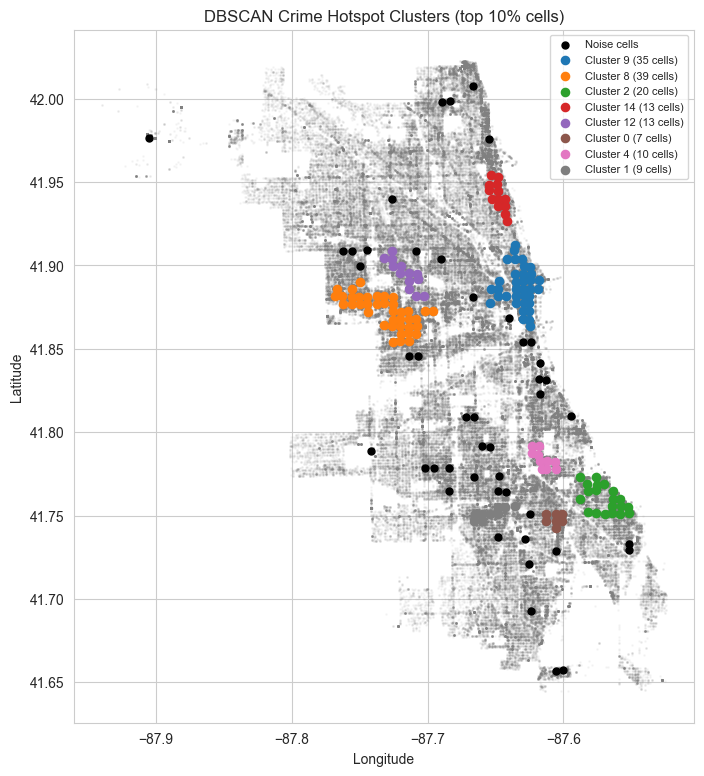

In [108]:
plt.figure(figsize=(8, 9))
plt.scatter(df["longitude"], df["latitude"], s=1, alpha=0.05, color="gray")

noise = cells[cells["cluster"] == -1]
plt.scatter(noise["longitude"], noise["latitude"], s=25, color="black", label="Noise cells")

big = summary.head(8).index
for c in big:
    sub = cells[cells["cluster"] == c]
    plt.scatter(sub["longitude"], sub["latitude"], s=35, label=f"Cluster {c} ({len(sub)} cells)")

plt.title("DBSCAN Crime Hotspot Clusters (top 10% cells)")
plt.xlabel("Longitude"); plt.ylabel("Latitude")
plt.legend(fontsize=8)
plt.show()

**Observation:**
- DBSCAN grouped the **230 hotspot cells** into **18 clusters**, and **46 cells** were noise (isolated hotspots that are not close to other hotspot cells).
- By crime count, the largest cluster is **Cluster 9** (35 cells, **19,181 crimes**, **8.2%** of all crimes in the city). By area, the largest is **Cluster 8** (39 cells, 5.5% of all crimes), on the west side.
- The **10 biggest clusters together hold about 25%** of all crimes of the city, although they cover only a small part of the map.
- So crime hotspots form **connected zones** rather than random single points, which helps police plan patrol areas instead of single locations.
- The result depends on `eps` and `min_samples`; a different value will give different clusters.

## 10. Model Improvement
### Hyperparameter Tuning

In [109]:
from sklearn.model_selection import ParameterGrid

weeks = sorted(panel["week_idx"].unique())

# Keep final 20% weeks for testing
train_weeks, test_weeks = train_test_split(
    weeks,
    train_size=0.80,
    shuffle=False
)

# Split training data into fit and validation periods
fit_weeks, val_weeks = train_test_split(
    train_weeks,
    train_size=0.80,
    shuffle=False
)

train = panel[panel["week_idx"].isin(fit_weeks)]
val = panel[panel["week_idx"].isin(val_weeks)]

X_fit, y_fit = train[features], train["crime_count"]
X_val, y_val = val[features], val["crime_count"]

tuning_results = []

# Random Forest tuning
rf_params = {
    "n_estimators": [100, 200],
    "max_depth": [8, 12]
}

for params in ParameterGrid(rf_params):

    model = RandomForestRegressor(
        **params,
        n_jobs=-1,
        random_state=42
    )

    model.fit(X_fit, y_fit)
    pred = model.predict(X_val)

    tuning_results.append({
        "Model": "Random Forest",
        "Parameters": str(params),
        "MAE": mean_absolute_error(y_val, pred),
        "RMSE": np.sqrt(mean_squared_error(y_val, pred))
    })

# XGBoost tuning
xgb_params = {
    "n_estimators": [200, 300],
    "max_depth": [4, 6],
    "learning_rate": [0.05]
}

for params in ParameterGrid(xgb_params):

    model = XGBRegressor(
        **params,
        subsample=0.8,
        random_state=42
    )

    model.fit(X_fit, y_fit)
    pred = model.predict(X_val)

    tuning_results.append({
        "Model": "XGBoost",
        "Parameters": str(params),
        "MAE": mean_absolute_error(y_val, pred),
        "RMSE": np.sqrt(mean_squared_error(y_val, pred))
    })

tuning_df = pd.DataFrame(tuning_results)

tuning_df.sort_values("MAE").round(3)


,Model,Parameters,MAE,RMSE
7,XGBoost,"{'learning_rate': 0.05, 'max_depth': 6, 'n_est...",1.572,2.134
6,XGBoost,"{'learning_rate': 0.05, 'max_depth': 6, 'n_est...",1.575,2.126
4,XGBoost,"{'learning_rate': 0.05, 'max_depth': 4, 'n_est...",1.579,2.097
5,XGBoost,"{'learning_rate': 0.05, 'max_depth': 4, 'n_est...",1.582,2.125
3,Random Forest,"{'max_depth': 12, 'n_estimators': 200}",1.583,2.124
2,Random Forest,"{'max_depth': 12, 'n_estimators': 100}",1.585,2.124
1,Random Forest,"{'max_depth': 8, 'n_estimators': 200}",1.586,2.121
0,Random Forest,"{'max_depth': 8, 'n_estimators': 100}",1.587,2.125


**Observation (Hyperparameter Tuning):**
- Random Forest and XGBoost were tested with 8 parameter combinations on a **validation slice inside the training data** (the test data was never used for tuning).
- All settings give very similar MAE (**1.572 to 1.587**), so the model is **not very sensitive** to these parameters.
- The best MAE is from **XGBoost with n_estimators = 300, max_depth = 6, learning_rate = 0.05** (MAE = 1.572). Depth 4 gives the lowest RMSE (2.097), so the settings are very close.
- The tuned model gives the **same test result** as the default one (MAE 1.565, R² 0.443), because the default settings were already the best choice.

In [110]:

# Prepare complete training and final test data
train = panel[panel["week_idx"].isin(train_weeks)]
test = panel[panel["week_idx"].isin(test_weeks)]

X_train, y_train = train[features], train["crime_count"]
X_test, y_test = test[features], test["crime_count"]

# Train the best XGBoost model
best_xgb = XGBRegressor(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    random_state=42
)

best_xgb.fit(X_train, y_train)

# Final prediction
final_pred = best_xgb.predict(X_test)

# Evaluation
print("Final XGBoost Model Performance")
print("MAE:", mean_absolute_error(y_test, final_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, final_pred)))
print("R2:", r2_score(y_test, final_pred))


Final XGBoost Model Performance
MAE: 1.5647928714752197
RMSE: 2.2151421239994065
R2: 0.4433562755584717


       Feature  Importance
4  roll_4_mean    0.768159
7     cell_lon    0.050129
2        lag_3    0.042700
0        lag_1    0.034114
1        lag_2    0.033435
6     cell_lat    0.027585
3        lag_4    0.023649
5        month    0.020227


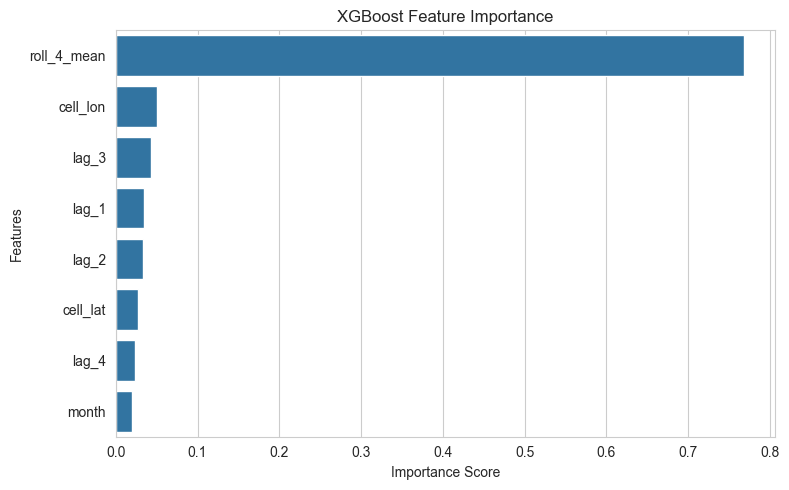

In [111]:
# Feature Importance of Tuned XGBoost Model

importance_df = pd.DataFrame({
    "Feature": features,
    "Importance": best_xgb.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance", ascending=False
)

print(importance_df)

plt.figure(figsize=(8, 5))
sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)
plt.title("XGBoost Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

### Observation

The feature importance analysis shows that `roll_4_mean` is the most influential feature, contributing approximately **76.82%** to the XGBoost model's feature importance. This indicates that the average crime count over the previous four weeks plays a major role in predicting future crime counts.

Other features, such as `cell_lon`, `lag_3`, `lag_1`, and `lag_2`, have relatively smaller contributions. The `month` feature has the lowest importance at approximately **2.02%**.

Overall, the model relies mainly on recent historical crime patterns rather than geographical and monthly features.

## 11. Grid Size Comparison

In [112]:
grid_sizes = {
    "250m": (0.00225, 0.003),
    "500m": (0.0045, 0.006),
    "1km": (0.009, 0.012)
}

grid_results = []

for name, (lat_step, lon_step) in grid_sizes.items():

    temp = df.copy()
    temp["week_idx"] = (
        (temp["date"].dt.normalize() - start).dt.days // 7
    )
    temp = temp[temp["week_idx"] < 52]          # only the 52 full weeks

    temp["cell_id"] = (
        (temp["latitude"] / lat_step).round().astype(int).astype(str)
        + "_" +
        (temp["longitude"] / lon_step).round().astype(int).astype(str)
    )

    weeks = sorted(temp["week_idx"].unique())[4:]
    train70, _ = train_test_split(
        weeks, train_size=0.70, shuffle=False
    )

    active = temp[
        temp["week_idx"].isin(train70)
    ]["cell_id"].value_counts()

    active = active[active >= 30].index

    p = (
        temp[temp["cell_id"].isin(active)]
        .groupby(["cell_id", "week_idx"])
        .size()
        .unstack(fill_value=0)
        .reindex(columns=range(52), fill_value=0)
        .stack()
        .reset_index(name="crime_count")
    )

    centers = temp.groupby("cell_id")[["latitude", "longitude"]].mean()
    centers.columns = ["cell_lat", "cell_lon"]
    p = p.join(centers, on="cell_id")

    g = p.groupby("cell_id")["crime_count"]

    for k in range(1, 5):
        p[f"lag_{k}"] = g.shift(k)

    p["roll_4_mean"] = g.transform(
        lambda s: s.shift(1).rolling(4).mean()
    )

    p["month"] = (
        start + pd.to_timedelta(p["week_idx"] * 7, unit="D")
    ).dt.month

    p = p.dropna()

    weeks = sorted(p["week_idx"].unique())
    train_w, test_w = train_test_split(
        weeks, train_size=0.80, shuffle=False
    )

    train = p[p["week_idx"].isin(train_w)]
    test = p[p["week_idx"].isin(test_w)]

    model = XGBRegressor(
        n_estimators=300, max_depth=6,
        learning_rate=0.05, subsample=0.8,
        random_state=42
    )

    model.fit(train[features], train["crime_count"])
    pred = model.predict(test[features])

    y_test_g = test["crime_count"]
    mae = mean_absolute_error(y_test_g, pred)

    grid_results.append({
        "Grid Size": name,
        "Active Cells": len(active),
        "Avg crimes per cell-week": y_test_g.mean(),
        "MAE": mae,
        "RMSE": np.sqrt(mean_squared_error(y_test_g, pred)),
        "MAE / Avg": mae / y_test_g.mean(),
        "R2": r2_score(y_test_g, pred)
    })

grid_comparison = pd.DataFrame(grid_results)
grid_comparison.round(3)

,Grid Size,Active Cells,Avg crimes per cell-week,MAE,RMSE,MAE / Avg,R2
0,250m,1485,1.566,1.098,1.450,0.701,0.300
1,500m,1458,2.979,1.565,2.215,0.525,0.443
2,1km,534,8.758,2.811,3.819,0.321,0.765


### Observation

The grid size comparison shows that different spatial resolutions produce different prediction results. Since MAE and RMSE depend on the average crime count of a cell, they **cannot be compared directly** across grid sizes. Therefore, **MAE/Avg** and **R²** are used for a fair comparison.

| Grid Size | Avg crimes per cell-week | MAE/Avg | R² |
|-----------|--------------------------|---------|-----|
| 250 m | 1.566 | 0.701 | 0.300 |
| 500 m | 2.979 | 0.525 | 0.443 |
| 1 km | 8.758 | 0.321 | 0.765 |

- Smaller cells have fewer crimes per week, so the data is sparse and harder to predict (lowest R² at 250 m).
- The **1 km** grid has the best R² and the lowest MAE/Avg, but each cell covers a large area, so the **location is less precise**.
- The **500 m** grid gives a good **balance between accuracy and spatial detail**.

Therefore, the **500 m × 500 m** grid is retained as the primary grid size for further analysis, while the other grid sizes are used only for comparison.

## 12. Final Results Summary
The table below combines the main results of the best regression model (**XGBoost**) and the hotspot classifier (**Random Forest**) for all three splits.

In [113]:
best_split = regression_results[regression_results["Model"] == "XGBoost"].set_index("Split")[["MAE", "RMSE", "R2"]]
clf_split = classification_df.set_index("Split")[["Accuracy", "F1 Score", "ROC-AUC"]]

final_summary = best_split.join(clf_split).round(3)
final_summary.columns = ["XGB MAE", "XGB RMSE", "XGB R2", "RF Accuracy", "RF F1", "RF ROC-AUC"]
final_summary

,XGB MAE,XGB RMSE,XGB R2,RF Accuracy,RF F1,RF ROC-AUC
Split,,,,,,
80:20,1.565,2.215,0.443,0.777,0.568,0.820
70:30,1.575,2.156,0.483,0.782,0.579,0.823
85:15,1.563,2.201,0.428,0.771,0.554,0.825


**Observation:**
- All three splits give **very similar results** (XGBoost MAE 1.56 to 1.58, RF F1 0.55 to 0.58, ROC-AUC about 0.82), so the model is **stable** and does not depend on one particular split.
- The **70:30 split** gives the best R² (0.483) and F1 (0.579), while **80:20** is used for the detailed analysis.

## 13. Conclusion

- We analysed **234,512 crime records** of Chicago (2022) and divided the city into **500 m grid cells**. Crime is **highly concentrated**: the busiest 10% of cells hold **34.1%** of all crimes.
- We predicted next-week crime count with **Random Forest and XGBoost**. **XGBoost** gave the lowest error in all three splits (MAE about **1.56**).
- A **4-week average baseline** was very strong (R² 0.46 to 0.49). So crime in an area depends mostly on **its own recent history**: `roll_4_mean` contributes about **76.8%** of XGBoost's feature importance.
- The **hotspot classifier** reached **F1 = 0.55 to 0.58** and **ROC-AUC about 0.82**, clearly better than the "last week" rule (F1 about 0.50). Among the 50 highest-risk cells each week, **86.6%** were real hotspots.
- The model finds **69%** of real hotspots, but it also gives many false alarms (precision 48%), so it predicts about **twice** as many hotspot cells as really occur.
- The **80:20, 70:30 and 85:15** splits gave very similar results, so the model is **stable**.
- A **500 m grid** gives a good balance between prediction accuracy and location detail.
- **DBSCAN** grouped the 230 busiest cells into **18 hotspot zones**. The 10 biggest zones hold about **25%** of all crimes of the city.

## 14. Limitations

- **Only reported crime** is in the data, and unreported crime is missing.
- Only **one year (2022)** was used, so yearly trends and seasonal patterns cannot be learned properly.
- The model uses only past crime counts, month and location. It does **not** use weather, population, events or police patrol data.
- Hour **0 and 12** timestamps are partly **recording artefacts**, so the hour-wise findings are less reliable.
- The classifier gives **many false alarms** (precision 48%) because it is tuned to catch hotspots.
- The model was trained on **Chicago data**, so its results should not be directly applied to Indian cities.
- Predictions are for **areas, not people**, and should support, not replace, human decisions.

## 15. Future Scope

- Use **more years** of data (for example 2018 to 2023) to learn long-term trends.
- Add **extra features**: weather, holidays, neighbouring-cell crime, population and nearby places.
- Try **time-series and deep-learning models** such as LSTM or Prophet.
- Predict **crime type-wise** hotspots (theft, battery and so on) and **day-wise or hour-wise** hotspots.
- Apply the same pipeline to **Indian city data** if incident-level data becomes available.
- **Deployed as a web app** with Streamlit so that users can view next-week hotspots; this can be extended into a dashboard for police.

## 16. Saving Files for Deployment
The files below are saved so that the model can be deployed as a **Streamlit web app**.

In [114]:

import os, json

os.makedirs("streamlit_app", exist_ok=True)

# 1. Save training data for the app
panel[["cell_id", "week_idx", "crime_count"] + features].to_csv(
    "streamlit_app/panel_train.csv", index=False
)

# 2. Recalculate coordinates using the original 500m grid
centers_500m = d.groupby("cell_id")[["latitude", "longitude"]].mean()
centers_500m.columns = ["cell_lat", "cell_lon"]

# 3. Prepare next-week forecast input
last = int(panel["week_idx"].max())

recent = panel[panel["week_idx"] > last - 4].pivot(
    index="cell_id",
    columns="week_idx",
    values="crime_count"
)

nxt = pd.DataFrame({
    "lag_1": recent[last],
    "lag_2": recent[last - 1],
    "lag_3": recent[last - 2],
    "lag_4": recent[last - 3]
})

nxt["roll_4_mean"] = nxt.mean(axis=1)

# Join correct 500m coordinates
nxt = nxt.join(centers_500m).reset_index()

# Save forecast input
nxt.to_csv("streamlit_app/next_week_input.csv", index=False)

# 4. Save model settings
hot_thr = float(
    panel[panel["week_idx"].isin(train_weeks_70)]["crime_count"].quantile(0.80)
)

with open("streamlit_app/meta.json", "w") as f:
    json.dump({"threshold": hot_thr, "features": features}, f)

print("Saved files:", os.listdir("streamlit_app"))
print("Cells for forecast:", len(nxt))
print("Missing latitude:", nxt["cell_lat"].isna().sum())
print("Missing longitude:", nxt["cell_lon"].isna().sum())
print("Hotspot threshold:", hot_thr)


Saved files: ['.ipynb_checkpoints', 'app.py', 'meta.json', 'next_week_input.csv', 'panel_train.csv', 'requirements.txt']
Cells for forecast: 1458
Missing latitude: 0
Missing longitude: 0
Hotspot threshold: 4.0


## 17. References

- City of Chicago Data Portal. *Crimes - 2001 to Present*. data.cityofchicago.org (dataset id ijzp-q8t2).
- Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825-2830.
- Chen, T. and Guestrin, C. (2016). XGBoost: A Scalable Tree Boosting System. *Proceedings of KDD 2016*.
- Ester, M. et al. (1996). A density-based algorithm for discovering clusters in large spatial databases with noise (DBSCAN). *Proceedings of KDD-96*.